# 04 — Análise de sensibilidade exploratória P95 × P97,5 × P99

Compara os limites temporais calibrados sobre maio mantendo a meta de 9,7 bar.

In [1]:
from pathlib import Path
import os, sys, zipfile, subprocess
BASE = Path.cwd()
if not (BASE / 'iot_monitor').exists():
    git_repo = "https://github.com/jorgek14/railpulse-metropt3.git"
    if git_repo.strip():
        subprocess.run(['git', 'clone', git_repo, '/content/railpulse-metropt3'], check=True)
        BASE = Path('/content/railpulse-metropt3')
    else:
        try:
            from google.colab import files
        except ImportError as e:
            raise RuntimeError('Abra o notebook na raiz do repositório ou no Colab e envie o ZIP do projeto.') from e
        print('Selecione o ZIP do repositório RailPulse. NÃO selecione o CSV original agora.')
        enviados = files.upload()
        nome = next((n for n in enviados if n.endswith('.zip')), None)
        assert nome, 'É necessário carregar o ZIP do projeto.'
        BASE = Path('/content/railpulse-metropt3')
        BASE.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(nome) as z:
            z.extractall(BASE)
os.chdir(BASE)
sys.path.insert(0, str(BASE))
print('Raiz do projeto:', BASE)

Raiz do projeto: /content/railpulse-metropt3


In [2]:
from pathlib import Path
CSV = BASE / 'dados' / 'MetroPT3(AirCompressor).csv'
if not CSV.exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        candidato = Path('/content/drive/MyDrive/MetroPT3(AirCompressor).csv')
        if candidato.exists(): CSV = candidato
    except ImportError:
        pass
assert CSV.exists(), 'Coloque MetroPT3(AirCompressor).csv em dados/ ou na raiz do Meu Drive.'
print('CSV:', CSV, 'MB:', round(CSV.stat().st_size/1e6, 1))

Mounted at /content/drive
CSV: /content/drive/MyDrive/MetroPT3(AirCompressor).csv MB: 218.3


In [3]:
import subprocess,sys
OUT=BASE/'resultados'/'sensibilidade';OUT.mkdir(parents=True,exist_ok=True)
subprocess.run([sys.executable,'analises/sensibilidade_regras.py','--csv',str(CSV),'--out',str(OUT)],check=True)

CompletedProcess(args=['/usr/bin/python3', 'analises/sensibilidade_regras.py', '--csv', '/content/drive/MyDrive/MetroPT3(AirCompressor).csv', '--out', '/content/railpulse-metropt3/resultados/sensibilidade'], returncode=0)

,percentil_calibracao,limiar_segundos,alertas_total,alertas_pre2h,alertas_fora_proximidades,eventos_pre2h,alertas_pre_F2,alertas_pre_F3,alertas_pre_F4
0,0.950,119.0,363,17,333,3,2,1,14
1,0.975,139.0,109,16,90,3,2,1,13
2,0.990,188.0,33,13,20,3,2,1,10


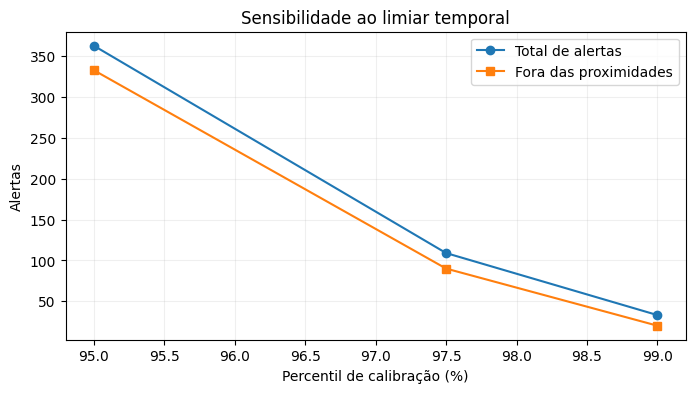

In [4]:
import pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
v=pd.read_csv(OUT/'sensibilidade_temporal_exploratoria.csv')
display(v)
assert list(v.alertas_total)==[363,109,33]
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(v.percentil_calibracao*100,v.alertas_total,'o-',label='Total de alertas')
ax.plot(v.percentil_calibracao*100,v.alertas_fora_proximidades,'s-',label='Fora das proximidades')
ax.set(xlabel='Percentil de calibração (%)',ylabel='Alertas',title='Sensibilidade ao limiar temporal');ax.legend();ax.grid(alpha=.2)
plt.show()